# **Project Topic: Digital Marketing Campaign Conversion Prediction**
By-
Deekshita R Parab

This project aims to built and develop a machine learning model that helps to predict whether a customer is likely to convert based on demographic information, campaign details, and customer engagement data. The aim is to help businesses identify potential customers, improve campaign targeting, increase conversion rates, and make better use of their advertising budget. It also includes various vizualizations, identifying Potential Converters and Optimising Marketing Strategies and feature importance.

In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Data Collection and Understanding**

The digital marketing campaign dataset was loaded into a Pandas DataFrame. It contains 8,000 customer records and 20 columns, including customer demographics, advertising spend, campaign details, engagement factors and conversion status. The dataset was initially checked to understand its structure, features, data types and target variable.

In [2]:
# Load the dataset

df = pd.read_csv("digital_marketing_campaign_dataset(in).csv")

In [3]:
# Display the first 5 rows

df.head()

,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [4]:
# Number of rows and columns

print("Dataset shape:", df.shape)

Dataset shape: (8000, 20)


In [5]:
# Column names

print("\nColumn names:")
print(df.columns.tolist())


Column names:
['CustomerID', 'Age', 'Gender', 'Income', 'CampaignChannel', 'CampaignType', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints', 'AdvertisingPlatform', 'AdvertisingTool', 'Conversion']


In [6]:
# Data types and non-null counts

print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           8000 non-null   int64  
 1   Age                  8000 non-null   int64  
 2   Gender               8000 non-null   object 
 3   Income               8000 non-null   int64  
 4   CampaignChannel      8000 non-null   object 
 5   CampaignType         8000 non-null   object 
 6   AdSpend              8000 non-null   float64
 7   ClickThroughRate     8000 non-null   float64
 8   ConversionRate       8000 non-null   float64
 9   WebsiteVisits        8000 non-null   int64  
 10  PagesPerVisit        8000 non-null   float64
 11  TimeOnSite           8000 non-null   float64
 12  SocialShares         8000 non-null   int64  
 13  EmailOpens           8000 non-null   int64  
 14  EmailClicks          8000 non-null   int64  
 15  PreviousPurchase


**Data Cleaning**

Data cleaning was performed to prepare the dataset for further analysis and modelling.
* Duplicate records were removed.
* ‘CustomerID’ column was removed because it is an identifier and is not any useful for prediction.
* ‘AdvertisingPlatform’ and ‘AdvertisingTool’ were removed because they contained the same constant values as IsConfid  and ToolConfid, which means confidential that, did not provide useful variations in the process.
* Missing values and duplicate records were checked.
After cleaning, the dataset had 8,000 rows and 17 columns, including the target variable. The cleaned dataset contains 16 input features and one target variable called‘Conversion’.

In [7]:
# Checking the number of unique values

print(df["AdvertisingPlatform"].nunique())
print(df["AdvertisingTool"].nunique())

1
1


In [8]:
# Data cleaning

df = df.drop_duplicates()

df = df.drop(columns=[
    "CustomerID",
    "AdvertisingPlatform",
    "AdvertisingTool"
])

print("Missing values:")
print(df.isnull().sum())

print("Duplicates:", df.duplicated().sum())
print("Dataset shape after cleaning:", df.shape)

Missing values:
Age                  0
Gender               0
Income               0
CampaignChannel      0
CampaignType         0
AdSpend              0
ClickThroughRate     0
ConversionRate       0
WebsiteVisits        0
PagesPerVisit        0
TimeOnSite           0
SocialShares         0
EmailOpens           0
EmailClicks          0
PreviousPurchases    0
LoyaltyPoints        0
Conversion           0
dtype: int64
Duplicates: 0
Dataset shape after cleaning: (8000, 17)


In [9]:
# Saving the cleaned dataset

df.to_csv("cleaned_digital_marketing_dataset.csv", index=False)

print("Cleaned dataset saved")

Cleaned dataset saved


In [10]:
# Counting each conversion class

print(df["Conversion"].value_counts())

Conversion
1    7012
0     988
Name: count, dtype: int64


In [11]:
# Calculated percentage of each class

print("\nConversion percentages:")
print(df["Conversion"].value_counts(normalize=True) * 100)


Conversion percentages:
Conversion
1    87.65
0    12.35
Name: proportion, dtype: float64


**Exploratory Data Analysis (EDA)**

Exploratory Data Analysis was performed to understand the customer behaviour and to identify patterns that are related to people’s conversion status.
The analysis includes:
* Examining the distribution of converted and non-converted customers.
* Calculating descriptive statistics for numerical features.
* Analysing numerical feature distributions and potential outliers.
* Comparing customer engagement factors between conversion groups.
* Examining conversion rates across categorical features such as Gender, CampaignChannel and CampaignType.
* Analysing correlations between numerical features.
The EDA showed that 87.65% of customers converted, while 12.35% did not convert showing an imbalance in the target variable.

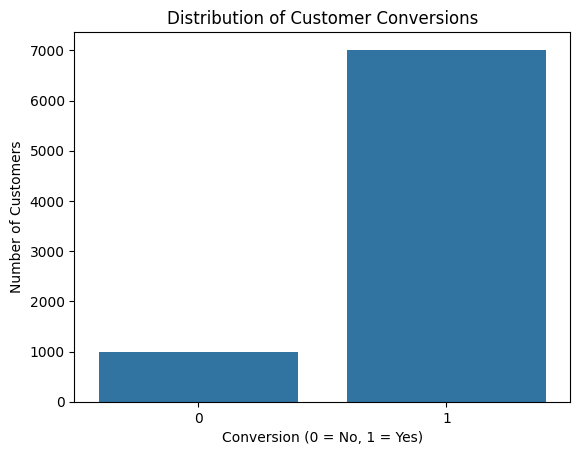

In [12]:
# plot

sns.countplot(data=df, x="Conversion")

plt.title("Distribution of Customer Conversions")
plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

In [13]:
df.describe().round(2)

,Age,Income,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,Conversion
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.0,8000.00,8000.00,8000.00,8000.00,8000.00
mean,43.63,84664.20,5000.94,0.15,0.10,24.75,5.55,7.73,49.8,9.48,4.47,4.49,2490.27,0.88
std,14.90,37580.39,2838.04,0.08,0.05,14.31,2.61,4.23,28.9,5.71,2.86,2.89,1429.53,0.33
min,18.00,20014.00,100.05,0.01,0.01,0.00,1.00,0.50,0.0,0.00,0.00,0.00,0.00,0.00
25%,31.00,51744.50,2523.22,0.08,0.06,13.00,3.30,4.07,25.0,5.00,2.00,2.00,1254.75,1.00
50%,43.00,84926.50,5013.44,0.15,0.10,25.00,5.53,7.68,50.0,9.00,4.00,4.00,2497.00,1.00
75%,56.00,116815.75,7407.99,0.23,0.15,37.00,7.84,11.48,75.0,14.00,7.00,7.00,3702.25,1.00
max,69.00,149986.00,9997.91,0.30,0.20,49.00,10.00,15.00,99.0,19.00,9.00,9.00,4999.00,1.00


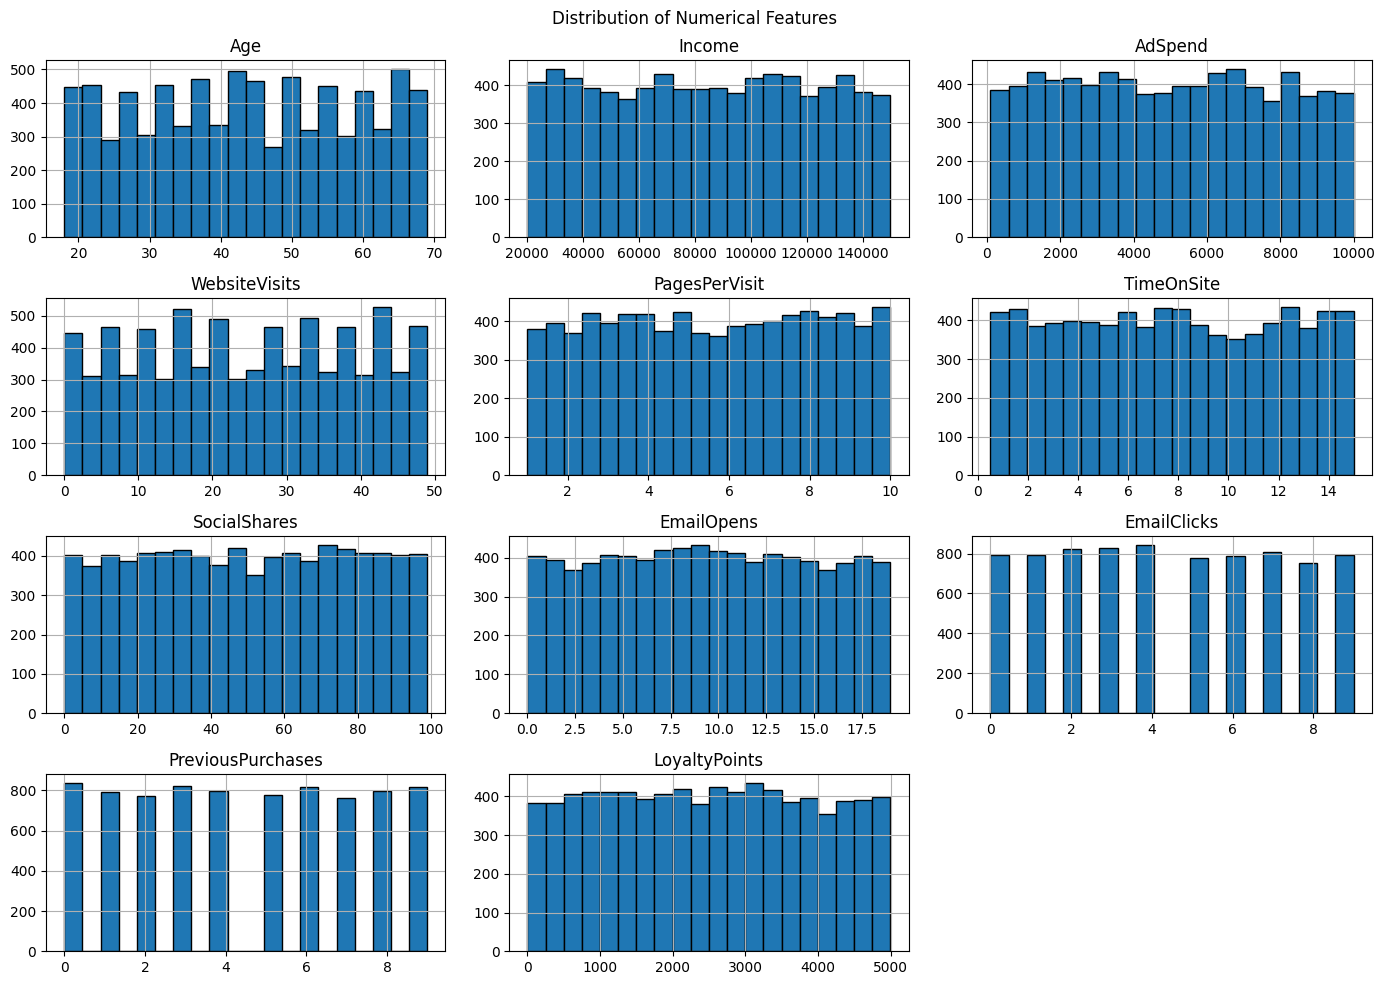

In [14]:
# plotted number of histograms

numerical_features = [
    "Age",
    "Income",
    "AdSpend",
    "WebsiteVisits",
    "PagesPerVisit",
    "TimeOnSite",
    "SocialShares",
    "EmailOpens",
    "EmailClicks",
    "PreviousPurchases",
    "LoyaltyPoints"
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

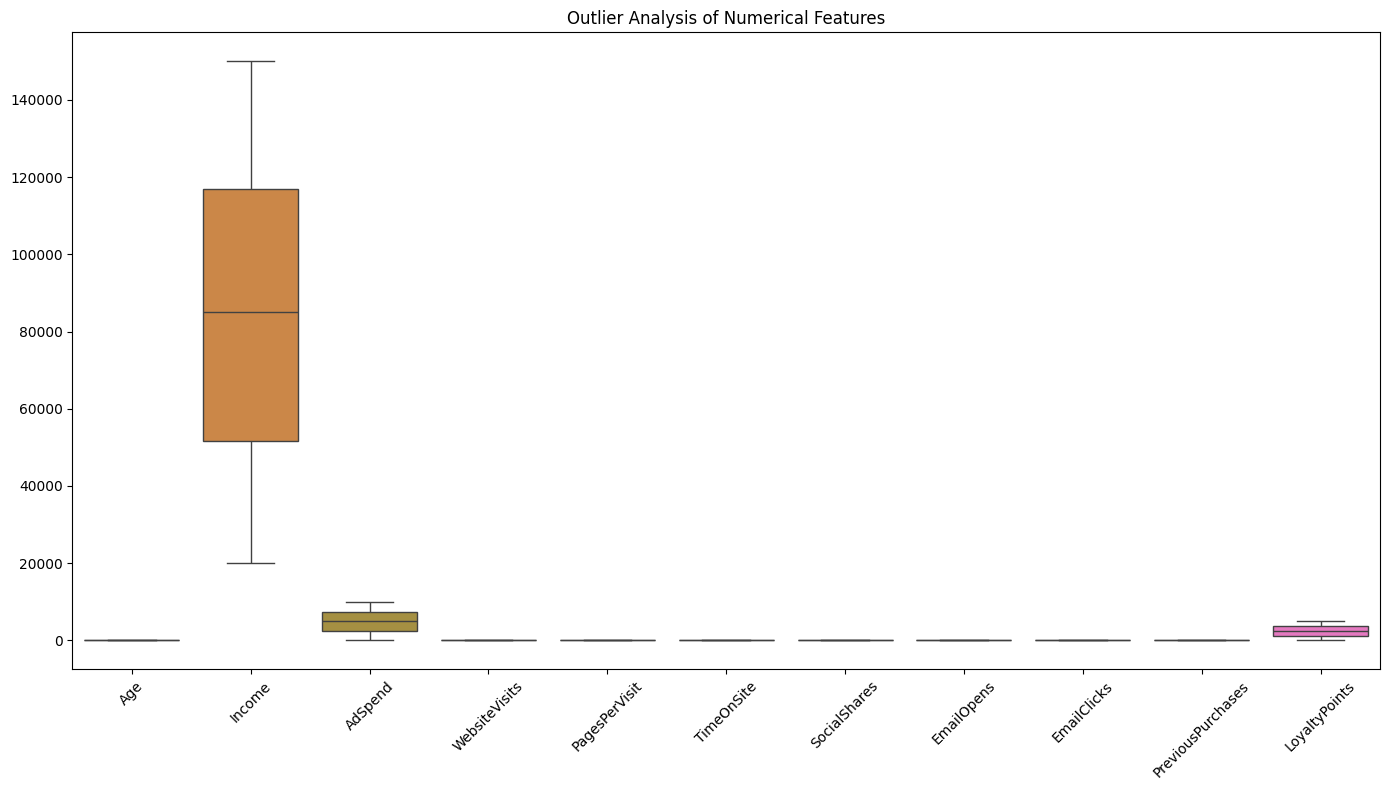

In [15]:
# Outlier analysis

plt.figure(figsize=(14, 8))
sns.boxplot(data=df[numerical_features])

plt.title("Outlier Analysis of Numerical Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
engagement_features = [
    "WebsiteVisits",
    "PagesPerVisit",
    "TimeOnSite",
    "SocialShares",
    "EmailOpens",
    "EmailClicks",
    "PreviousPurchases"
]

conversion_comparison = df.groupby("Conversion")[
    engagement_features
].mean().round(2)

print(conversion_comparison)

            WebsiteVisits  PagesPerVisit  TimeOnSite  SocialShares  \
Conversion                                                           
0                   21.73           4.84        6.27         50.68   
1                   25.18           5.65        7.93         49.68   

            EmailOpens  EmailClicks  PreviousPurchases  
Conversion                                              
0                 7.58         3.48               3.63  
1                 9.74         4.61               4.61  


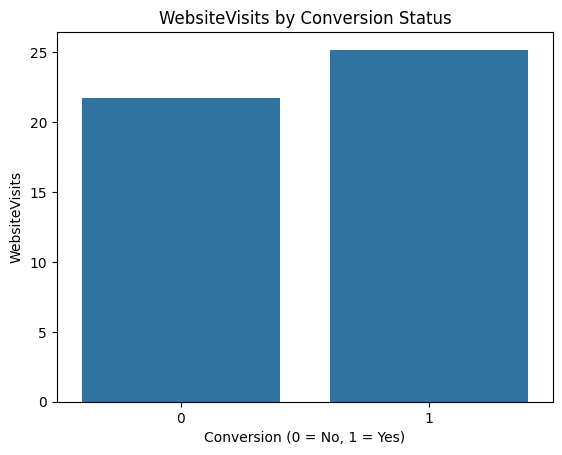

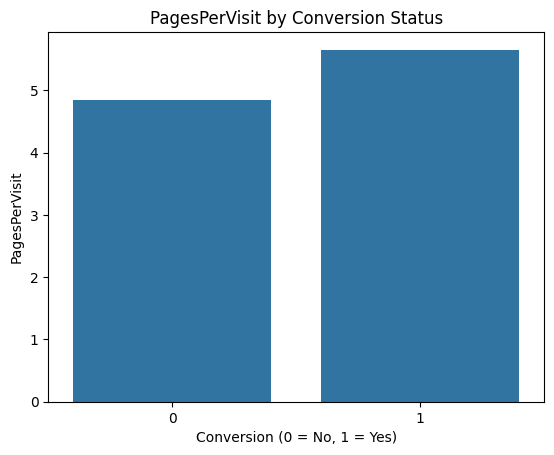

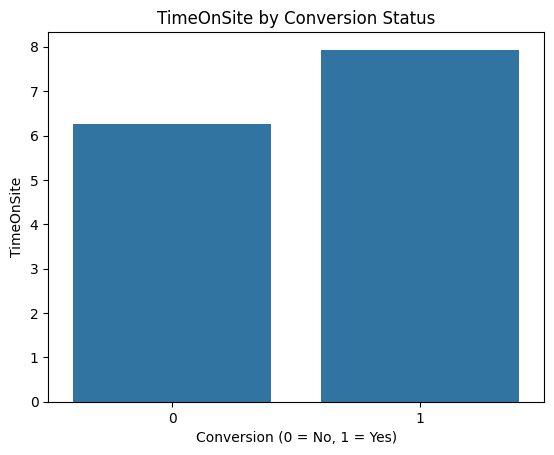

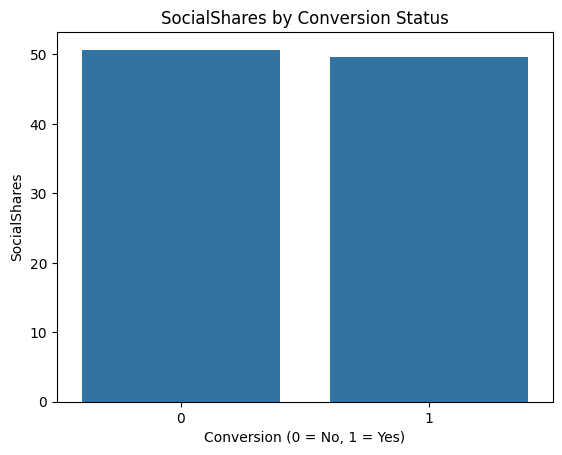

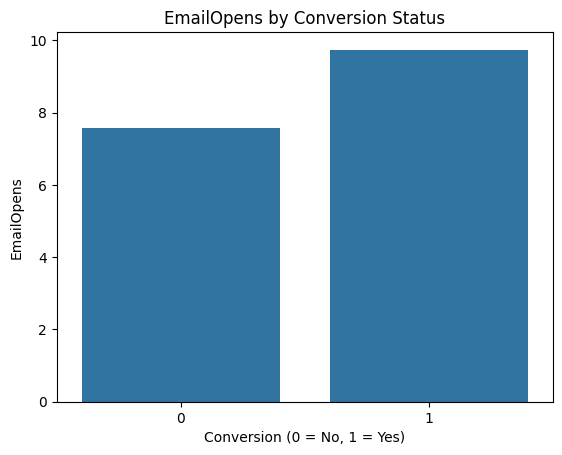

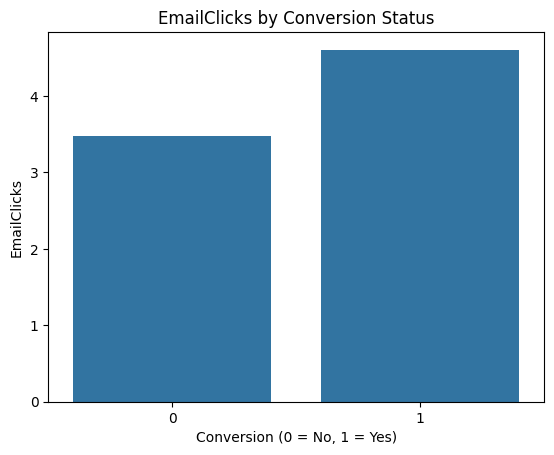

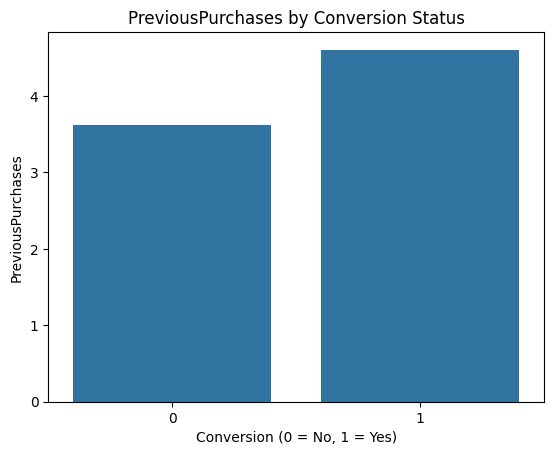

In [17]:
# plot

for feature in engagement_features:
    sns.barplot(
        data=df,
        x="Conversion",
        y=feature,
        errorbar=None
    )

    plt.title(f"{feature} by Conversion Status")
    plt.xlabel("Conversion (0 = No, 1 = Yes)")
    plt.ylabel(feature)
    plt.show()

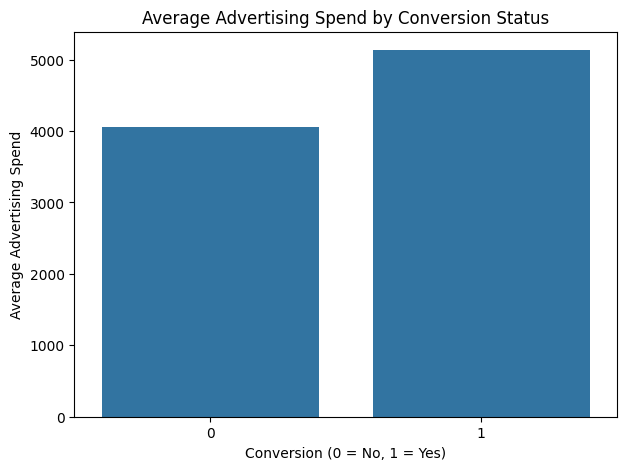

In [18]:
# plot

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Conversion",
    y="AdSpend",
    errorbar=None
)

plt.title("Average Advertising Spend by Conversion Status")

plt.xlabel("Conversion (0 = No, 1 = Yes)")

plt.ylabel("Average Advertising Spend")

plt.show()

In [19]:
# Categorical columns
categorical_features = [
    "Gender",
    "CampaignChannel",
    "CampaignType"
]

# Display the unique categories
for feature in categorical_features:
    print(f"\n{feature}:")
    print(df[feature].value_counts())


Gender:
Gender
Female    4839
Male      3161
Name: count, dtype: int64

CampaignChannel:
CampaignChannel
Referral        1719
PPC             1655
Email           1557
SEO             1550
Social Media    1519
Name: count, dtype: int64

CampaignType:
CampaignType
Conversion       2077
Awareness        1988
Consideration    1988
Retention        1947
Name: count, dtype: int64


In [20]:
for feature in categorical_features:
    conversion_rates = df.groupby(feature)["Conversion"].mean() * 100

    print(f"\nConversion rate by {feature}:")
    print(conversion_rates.round(2))


Conversion rate by Gender:
Gender
Female    87.62
Male      87.69
Name: Conversion, dtype: float64

Conversion rate by CampaignChannel:
CampaignChannel
Email           87.03
PPC             88.28
Referral        88.31
SEO             87.68
Social Media    86.83
Name: Conversion, dtype: float64

Conversion rate by CampaignType:
CampaignType
Awareness        85.56
Consideration    85.56
Conversion       93.36
Retention        85.82
Name: Conversion, dtype: float64


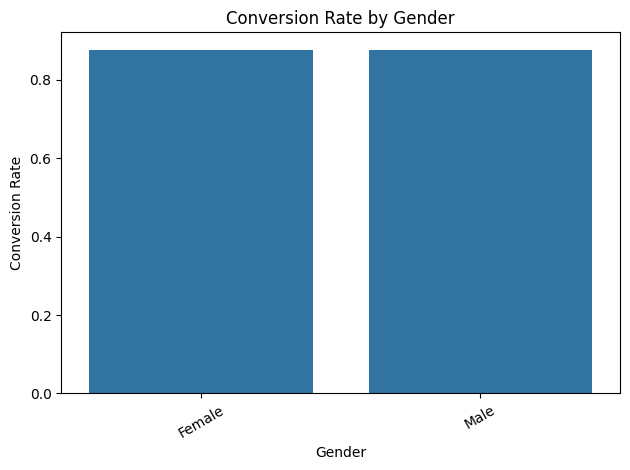

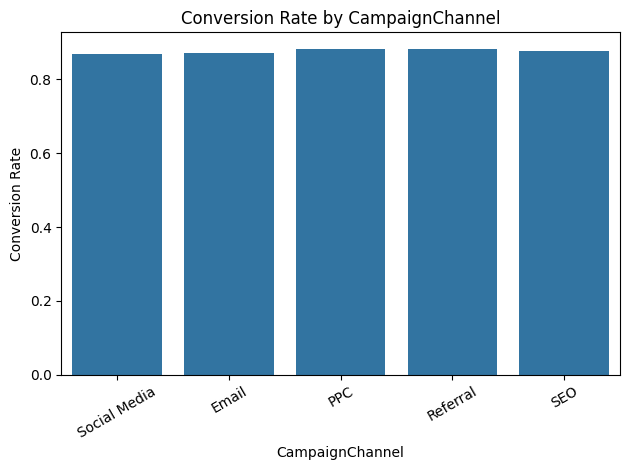

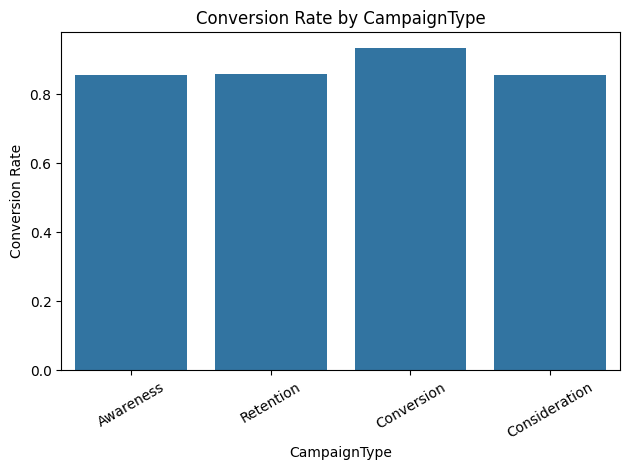

In [21]:
for feature in categorical_features:
    sns.barplot(
        data=df,
        x=feature,
        y="Conversion",
        errorbar=None
    )

    plt.title(f"Conversion Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Conversion Rate")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

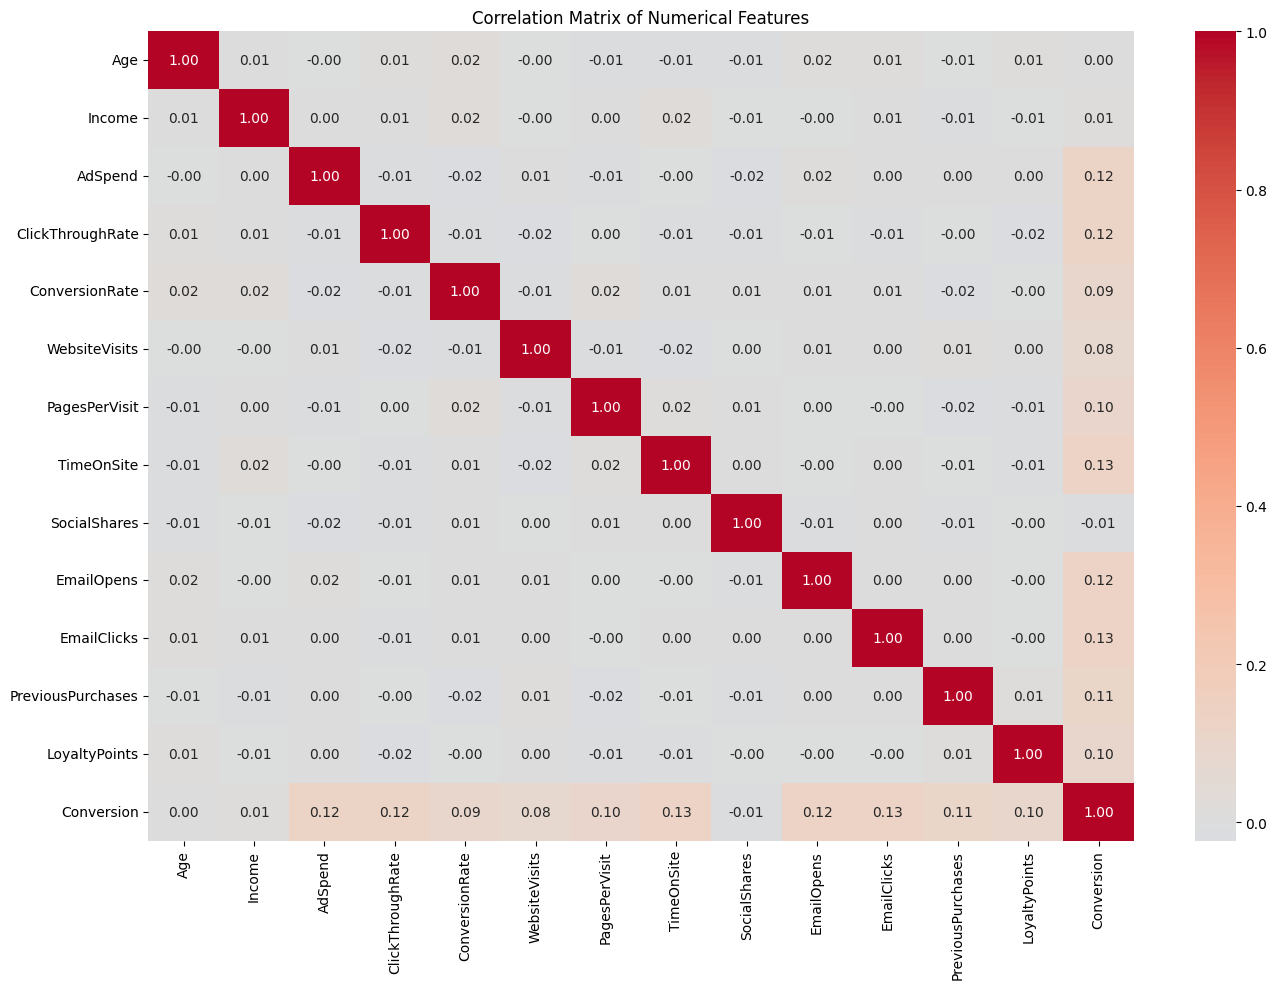

In [22]:
# correlation analysis

# Selected numerical columns
numerical_df = df.select_dtypes(include=["number"])

# Calculated correlations
correlation_matrix = numerical_df.corr()

# Plotted the correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [23]:
# Compared ConversionRate by target class
print(
    df.groupby("Conversion")["ConversionRate"]
      .agg(["mean", "median", "min", "max"])
)

# Compared ClickThroughRate by target class
print(
    df.groupby("Conversion")["ClickThroughRate"]
      .agg(["mean", "median", "min", "max"])
)

                mean    median       min       max
Conversion                                        
0           0.090766  0.081513  0.010018  0.199710
1           0.106308  0.106523  0.010059  0.199995
                mean    median       min       max
Conversion                                        
0           0.127972  0.103357  0.010535  0.299216
1           0.158613  0.159202  0.010005  0.299968


In [24]:
# Conversion rate by campaign channel
print("Conversion rate by CampaignChannel:")
print(
    (df.groupby("CampaignChannel")["Conversion"].mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

# Conversion rate by campaign type
print("\nConversion rate by CampaignType:")
print(
    (df.groupby("CampaignType")["Conversion"].mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

Conversion rate by CampaignChannel:
CampaignChannel
Referral        88.31
PPC             88.28
SEO             87.68
Email           87.03
Social Media    86.83
Name: Conversion, dtype: float64

Conversion rate by CampaignType:
CampaignType
Conversion       93.36
Retention        85.82
Consideration    85.56
Awareness        85.56
Name: Conversion, dtype: float64


In [25]:
# prechecking before modelling
# Checking categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())

Categorical columns: ['Gender', 'CampaignChannel', 'CampaignType']

Gender:
Gender
Female    4839
Male      3161
Name: count, dtype: int64

CampaignChannel:
CampaignChannel
Referral        1719
PPC             1655
Email           1557
SEO             1550
Social Media    1519
Name: count, dtype: int64

CampaignType:
CampaignType
Conversion       2077
Awareness        1988
Consideration    1988
Retention        1947
Name: count, dtype: int64


**Data Preprocessing**

The target variable ‘Conversion’ was separated from the input features and the dataset was divided into 80% training data and 20% testing data using train_test_split. This means that 6,400 records were used for training and 1,600 records were used for testing. Stratified sampling was applied to maintain the original class distribution in both datasets.
One-Hot Encoding was applied to categorical features such as Gender, CampaignChannel and CampaignType. One-Hot Encoding converts categorical values into numerical columns that machine learning algorithms can process.
Numerical features were passed through without scaling for the tree-based models. StandardScaler was applied to numerical features in the Logistic Regression pipeline because Logistic Regression is sensitive to differences in feature scales.
A preprocessing pipeline was used to combine these transformation changes with the machine learning algorithms. The preprocessing steps were included in Scikit-learn pipelines to ensure that the same transformations were applied consistently during training and prediction.

**Model Building**

Five machine learning algorithms were implemented:
* Random Forest
* Decision Tree
* Logistic Regression
* XGBoost
* AdaBoost


**1. Random Forest**

It was selected because it combines multiple decision trees to improve prediction performance. It can capture complex relationships between customer features and conversion outcomes.

In [26]:
# Feature scaling and Random Forest

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix

# Features and target
y = df["Conversion"]
X = df.drop(columns=["Conversion"])

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("Feature columns:", X.columns.tolist())

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify categorical and numerical features
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Convert categorical values into numbers
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", "passthrough", numerical_cols)
])

# Preprocessing for Logistic Regression

lr_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numerical_cols)
])

# Create the model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Store model results
model_results = []

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

model_results.append({
    "Model": "Random Forest",
    "Macro F1": f1_score(y_test, y_pred, average="macro")
})

print("Macro F1 Score:", round(
    f1_score(y_test, y_pred, average="macro"), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Feature dataset shape: (8000, 16)
Target dataset shape: (8000,)
Feature columns: ['Age', 'Gender', 'Income', 'CampaignChannel', 'CampaignType', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints']
Macro F1 Score: 0.5154

Confusion Matrix:
[[  10  188]
 [   3 1399]]


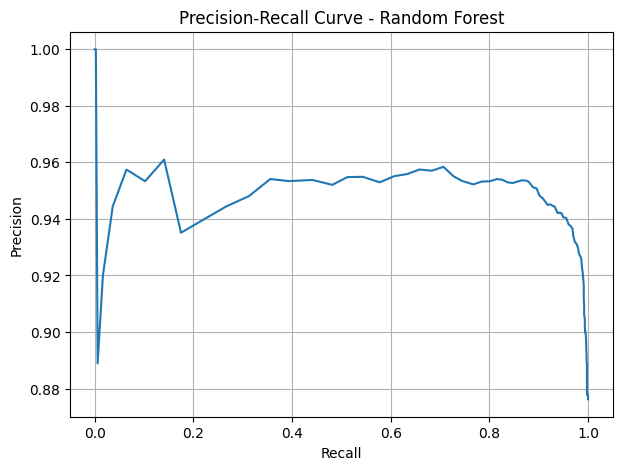

In [27]:
# Random Forest Precision-Recall Curve

from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

y_prob_rf = model.predict_proba(X_test)[:, 1]

precision_rf, recall_rf, thresholds_rf = precision_recall_curve(
    y_test, y_prob_rf
)

plt.figure(figsize=(7, 5))
plt.plot(recall_rf, precision_rf)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest")
plt.grid()
plt.show()


**2. Decision Tree**

Decision Tree was selected because it is a simple and interpretable classification algorithm. It uses decision rules based on input features to classify customers.

In [28]:
# Decision tree model

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

dt_pred = decision_tree_model.predict(X_test)

model_results.append({
    "Model": "Decision Tree",
    "Macro F1": f1_score(y_test, dt_pred, average="macro")
})

print("Macro F1 Score:", round(
    f1_score(y_test, dt_pred, average="macro"), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))


Macro F1 Score: 0.6169

Confusion Matrix:
[[  64  134]
 [ 129 1273]]


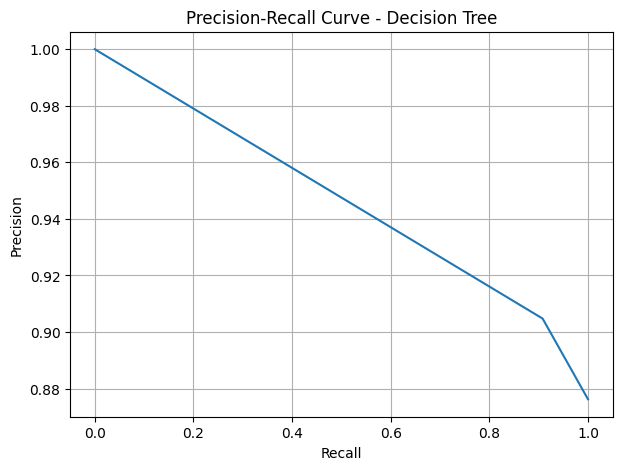

In [29]:
# Decision tree precision-recall curve
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

precision_dt, recall_dt, thresholds_dt = precision_recall_curve(
    y_test, y_prob_dt
)

plt.figure(figsize=(7, 5))
plt.plot(recall_dt, precision_dt)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Decision Tree")
plt.grid()
plt.show()

**3. Logistic Regression**

Logistic Regression was selected as a baseline classification algorithm. It estimates the probability of a customer belonging to the converted or non-converted class and provides a useful comparison with more complex models.

In [30]:
# Logistic regression model

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", clone(lr_preprocessor)),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Trained the model

logistic_model.fit(X_train, y_train)

# Predict

lr_pred = logistic_model.predict(X_test)

model_results.append({
    "Model": "Logistic Regression",
    "Macro F1": f1_score(y_test, lr_pred, average="macro")
})

print("Macro F1 Score:", round(
    f1_score(y_test, lr_pred, average="macro"), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Macro F1 Score: 0.6337

Confusion Matrix:
[[ 145   53]
 [ 341 1061]]


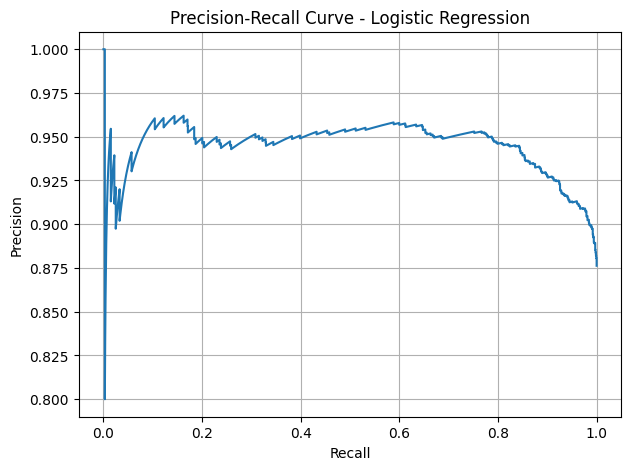

In [31]:
# Logistic regression precision recall curve

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

precision_lr, recall_lr, thresholds_lr = precision_recall_curve(
    y_test, y_prob_lr
)

plt.figure(figsize=(7, 5))
plt.plot(recall_lr, precision_lr)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.grid()
plt.show()

In [32]:
# xgBoost
%pip install xgboost

**4. XGBoost**

XGBoost was selected because it uses a gradient boosting approach to build decision trees sequentially. It can capture complex patterns in structured datasets and improve predictions by learning from previous errors.

In [33]:
#xgboost

from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

model_results.append({
    "Model": "XGBoost",
    "Macro F1": f1_score(y_test, xgb_pred, average="macro")
})

print("Macro F1 Score:", round(
    f1_score(y_test, xgb_pred, average="macro"), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

Macro F1 Score: 0.7416

Confusion Matrix:
[[  76  122]
 [  13 1389]]


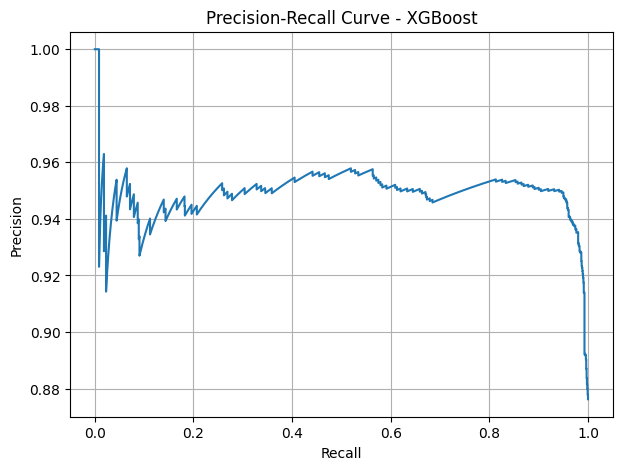

In [34]:
# XGBoost precision recall curve

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

precision_xgb, recall_xgb, thresholds_xgb = precision_recall_curve(
    y_test, y_prob_xgb
)

plt.figure(figsize=(7, 5))
plt.plot(recall_xgb, precision_xgb)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - XGBoost")
plt.grid()
plt.show()

**5. AdaBoost**

AdaBoost was selected as another boosting-based algorithm. It combines multiple weak learners and gives additional attention to incorrectly classified observations.

In [35]:
# AdaBoost

from sklearn.ensemble import AdaBoostClassifier

ada_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.5,
        random_state=42
    ))
])

ada_model.fit(X_train, y_train)

ada_pred = ada_model.predict(X_test)

model_results.append({
    "Model": "AdaBoost",
    "Macro F1": f1_score(y_test, ada_pred, average="macro")
})

print("Macro F1 Score:", round(
    f1_score(y_test, ada_pred, average="macro"), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ada_pred))

Macro F1 Score: 0.5797

Confusion Matrix:
[[  25  173]
 [   5 1397]]


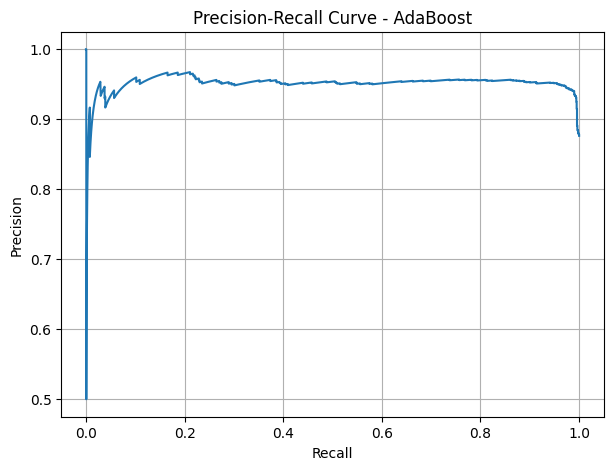

In [36]:
# AdaBoost Precision-recall curve

y_prob_ada = ada_model.predict_proba(X_test)[:, 1]

precision_ada, recall_ada, thresholds_ada = precision_recall_curve(
    y_test, y_prob_ada
)

plt.figure(figsize=(7, 5))
plt.plot(recall_ada, precision_ada)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - AdaBoost")
plt.grid()
plt.show()

**Model Evaluation**

The models were evaluated using the following performance metrics:
* Macro F1 Score: Calculates the F1 score for each class and gives equal importance to both classes of the conversion status 0 and 1, as the target variable here is imbalanced, unlike the regular F1 score, which gives weightage to only status 1.
* Confusion Matrix: Shows correct and incorrect predictions for each class.
* Precision-Recall Curve: Evaluates the relationship between precision and recall at different classification thresholds.

In [37]:
# Model Comparison

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
)

print("Model Comparison:")
print(results_df.round(4))

Model Comparison:
                 Model  Macro F1
3              XGBoost    0.7416
2  Logistic Regression    0.6337
1        Decision Tree    0.6169
4             AdaBoost    0.5797
0        Random Forest    0.5154


**Model Selection and Justification**


Five classification algorithms, namely Random Forest, Decision Tree, Logistic Regression, XGBoost and AdaBoost, were trained and evaluated. Their performance was compared using Macro F1 Score, Confusion Matrix and Precision-Recall Curves. XGBoost achieved the highest initial Macro F1 Score of 0.7416 and was selected for further hyperparameter tuning. RandomizedSearchCV with 5-fold Stratified Cross-Validation was used to identify the best hyperparameters.


In [38]:
# hyperparameter tuning on stadard xgboost

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_grid = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.15],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0],
    "classifier__min_child_weight": [1, 3, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [39]:
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

best_xgb_model = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.8}

Best Cross-Validation Macro F1:
0.7801021678118255


In [40]:
# Tuned XGBoost Evaluation

y_pred_tuned = best_xgb_model.predict(X_test)

macro_f1 = f1_score(
    y_test, y_pred_tuned, average="macro"
)

print("Tuned XGBoost Results")
print("----------------------")

print("Macro F1 Score:", round(macro_f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned XGBoost Results
----------------------
Macro F1 Score: 0.768

Confusion Matrix:
[[  86  112]
 [  13 1389]]


In [41]:
cm = confusion_matrix(y_test, y_pred_tuned)
print(cm)

cm_long = pd.DataFrame([
    ["Not Converted", "Not Converted", cm[0, 0]],
    ["Not Converted", "Converted", cm[0, 1]],
    ["Converted", "Not Converted", cm[1, 0]],
    ["Converted", "Converted", cm[1, 1]]
], columns=["Actual Class", "Predicted Class", "Count"])

cm_long.to_csv("confusion_matrix.csv", index=False)

[[  86  112]
 [  13 1389]]


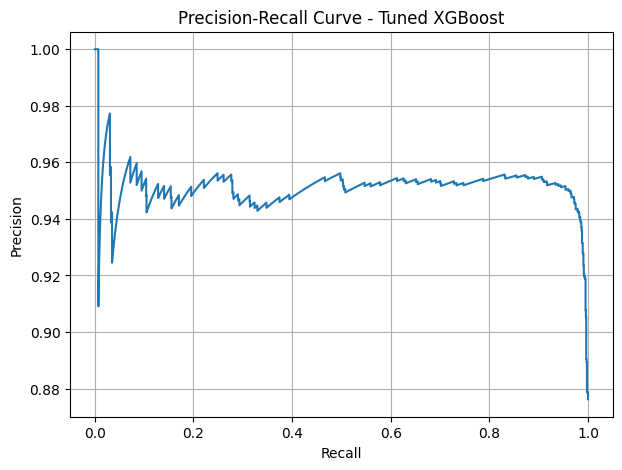

In [42]:
# Tuned XGBoost Precision-Recall Curve

y_prob_tuned = best_xgb_model.predict_proba(X_test)[:, 1]

precision_tuned, recall_tuned, thresholds_tuned = precision_recall_curve(
    y_test, y_prob_tuned
)

plt.figure(figsize=(7, 5))
plt.plot(recall_tuned, precision_tuned)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Tuned XGBoost")
plt.grid()
plt.show()

In [43]:
# Compared Standard and Tuned XGBoost

original_pred = xgb_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Original XGBoost", "Tuned XGBoost"],
    "Macro F1": [
        f1_score(y_test, original_pred, average="macro"),
        f1_score(y_test, y_pred_tuned, average="macro")
    ]
})

print(comparison)

              Model  Macro F1
0  Original XGBoost  0.741636
1     Tuned XGBoost  0.768033


In [44]:
model_results.append({
    "Model": "Tuned XGBoost",
    "Macro F1": f1_score(
        y_test, y_pred_tuned, average="macro"
    )
})

# Final Model Comparison

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
)

print("Final Model Comparison:")
print(results_df.round(4))

Final Model Comparison:
                 Model  Macro F1
5        Tuned XGBoost    0.7680
3              XGBoost    0.7416
2  Logistic Regression    0.6337
1        Decision Tree    0.6169
4             AdaBoost    0.5797
0        Random Forest    0.5154


**Final Selection of Model**

Tuned XGBoost was selected as the final model because it achieved the highest Macro F1 score of 0.7680 and an Accuracy of 92.19% on the test dataset. Its performance indicates a better balance between identifying converted and non-converted customers compared with the other evaluated models, based on Macro F1. Therefore, the tuned XGBoost model was selected for the final customer conversion prediction application and subsequent deployment using Streamlit.

**Identifying Potential Converters and Optimising Marketing Strategies**

The Tuned XGBoost model was used to predict the probability of customer conversion based on demographic, campaign and engagement features. Based on these predicted probabilities, customers were divided into three priority groups:
* High Priority: Conversion probability of 70% or above.
* Medium Priority: Conversion probability between 40% and 69%.
* Low Priority: Conversion probability below 40%.
The actual conversion rates were then analysed for each group to understand how well the segmentation identified potential converters.

The results showed that the High Priority group had the highest actual conversion rate of 95.06%, while the Low Priority group had the lowest at 10.14%.
This analysis demonstrates how machine learning predictions can help businesses identify potential converters, prioritise customers for marketing campaigns, and consider targeted offers or follow-ups for different customer groups.


In [45]:
# increased conversion rates

# Predicted conversion probabilities
y_prob = best_xgb_model.predict_proba(X_test)[:, 1]

# Created a results DataFrame
conversion_results = X_test.copy()

conversion_results["Actual Conversion"] = y_test
conversion_results["Predicted Probability"] = y_prob

# Categorised customers based on predicted probability
conversion_results["Customer Priority"] = np.where(
    y_prob >= 0.70,
    "High Priority",
    np.where(y_prob >= 0.40, "Medium Priority", "Low Priority")
)

# Displayed results
print(conversion_results[
    ["Actual Conversion", "Predicted Probability", "Customer Priority"]
].head(10))

      Actual Conversion  Predicted Probability Customer Priority
3344                  1               0.908906     High Priority
408                   1               0.983251     High Priority
5038                  1               0.990277     High Priority
6499                  0               0.282200      Low Priority
4266                  1               0.981169     High Priority
3444                  1               0.837192     High Priority
4766                  1               0.937784     High Priority
3672                  1               0.965326     High Priority
2774                  1               0.964403     High Priority
3033                  1               0.995964     High Priority


Customer Priority
High Priority      1416
Medium Priority     115
Low Priority         69
Name: count, dtype: int64


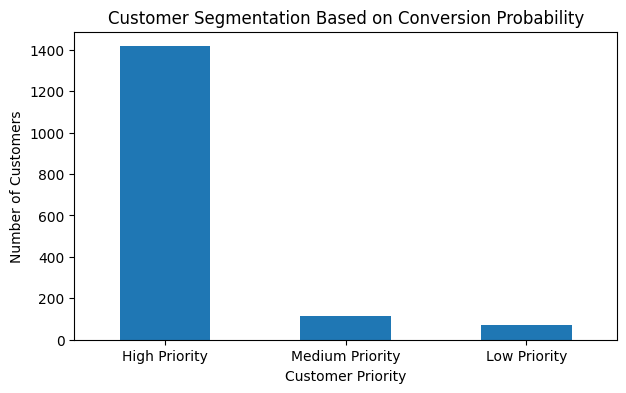

In [46]:
# Counted customers in each priority group
priority_counts = conversion_results["Customer Priority"].value_counts()

print(priority_counts)

# Plotted customer priority groups
priority_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Customer Segmentation Based on Conversion Probability")
plt.xlabel("Customer Priority")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [47]:
# Analysed actual conversion rates in each priority group

priority_analysis = conversion_results.groupby(
    "Customer Priority"
)["Actual Conversion"].agg(
    ["count", "sum", "mean"]
)

priority_analysis["Conversion Rate (%)"] = (
    priority_analysis["mean"] * 100
)

print(priority_analysis)

                   count   sum      mean  Conversion Rate (%)
Customer Priority                                            
High Priority       1416  1346  0.950565            95.056497
Low Priority          69     7  0.101449            10.144928
Medium Priority      115    49  0.426087            42.608696


**Feature Importance**

Feature importance was analysed using the final Tuned XGBoost model to identify the features that contributed most to its predictions. The important features included Previous Purchases, Email Clicks, Campaign Type (Converted), Email Opens, Click-Through Rate, Time on Site, Website Visits and Ad Spend. This analysis highlights the importance of customer purchase history and engagement activities in predicting conversions. These insights can help businesses identify potential customers and make better campaign-targeting decisions.

In [48]:
# feature importance

# Got the XGBoost classifier from the tuned pipeline
xgb_classifier = best_xgb_model.named_steps["classifier"]

# Got feature names after preprocessing
feature_names = best_xgb_model.named_steps["preprocessing"].get_feature_names_out()

# Got feature importance values
importances = xgb_classifier.feature_importances_

# Created a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sorted features by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Displayed feature importance
print(feature_importance_df)

                              Feature  Importance
22             num__PreviousPurchases    0.086711
21                   num__EmailClicks    0.078115
9        cat__CampaignType_Conversion    0.077313
20                    num__EmailOpens    0.060105
14              num__ClickThroughRate    0.057075
18                    num__TimeOnSite    0.054773
16                 num__WebsiteVisits    0.053385
13                       num__AdSpend    0.053285
17                 num__PagesPerVisit    0.051678
15                num__ConversionRate    0.050495
23                 num__LoyaltyPoints    0.049692
2          cat__CampaignChannel_Email    0.036003
0                  cat__Gender_Female    0.029024
1                    cat__Gender_Male    0.027606
7         cat__CampaignType_Awareness    0.027321
8     cat__CampaignType_Consideration    0.026750
10        cat__CampaignType_Retention    0.026530
3            cat__CampaignChannel_PPC    0.025183
19                  num__SocialShares    0.024897


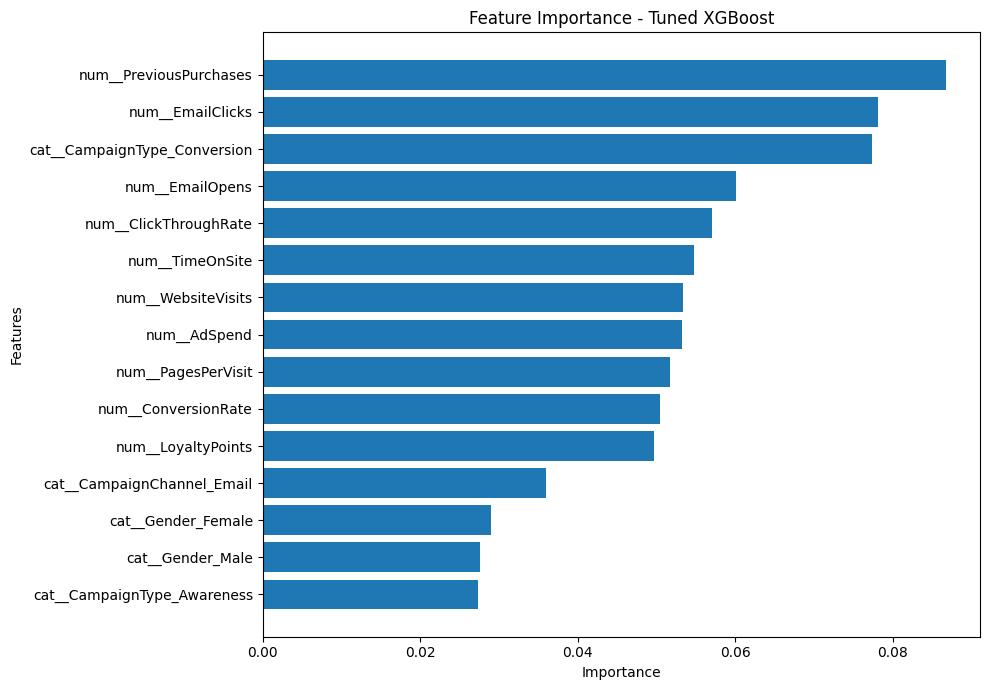

In [49]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance_df["Feature"].head(15)[::-1],
    feature_importance_df["Importance"].head(15)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Feature Importance - Tuned XGBoost")

plt.tight_layout()
plt.show()

In [50]:
print("Final Model Selected: Tuned XGBoost")

Final Model Selected: Tuned XGBoost


In [51]:
import joblib

joblib.dump(best_xgb_model, "best_xgboost_model.joblib")

print("Tuned model saved")

Tuned model saved


In [52]:
from google.colab import files

files.download("best_xgboost_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Model Deployment**

The final tuned XGBoost pipeline was saved using Joblib.
A Streamlit application was developed to allow users to enter customer and campaign information and receive a conversion prediction message.
This provides an interactive way to demonstrate the practical application of the trained machine learning model.

In [53]:
# For Streamlit app

%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load the trained model
model = joblib.load("best_xgboost_model.joblib")

st.title("Digital Marketing Campaign Conversion Prediction")

st.write(
    "Enter customer and campaign details to predict "
    "whether a customer is likely to convert."
)

# Customer details
st.header("Customer Details")

age = st.number_input(
    "Age", min_value=18, max_value=69, value=30
)

gender = st.selectbox("Gender", ["Female", "Male"])

income = st.number_input(
    "Income", min_value=20014, max_value=149986, value=50000
)

# Campaign details
st.header("Campaign Details")

campaign_channel = st.selectbox(
    "Campaign Channel",
    ["Email", "Social Media", "SEO", "PPC", "Referral"]
)

campaign_type = st.selectbox(
    "Campaign Type",
    ["Awareness", "Consideration", "Conversion", "Retention"]
)

ad_spend = st.number_input(
    "Ad Spend", min_value=100.05, max_value=9997.91, value=1000.0
)

click_through_rate = st.number_input(
    "Click Through Rate",
    min_value=0.01, max_value=0.30, value=0.15
)

conversion_rate = st.number_input(
    "Conversion Rate",
    min_value=0.01, max_value=0.20, value=0.10
)

# Customer engagement
st.header("Customer Engagement")

website_visits = st.number_input(
    "Website Visits", min_value=0, max_value=49, value=10
)

pages_per_visit = st.number_input(
    "Pages Per Visit", min_value=0.0, max_value=10.0, value=3.0
)

time_on_site = st.number_input(
    "Time on Site", min_value=0.0, max_value=15.0, value=5.0
)

social_shares = st.number_input(
    "Social Shares", min_value=0, max_value=99, value=5
)

email_opens = st.number_input(
    "Email Opens", min_value=0, max_value=19, value=5
)

email_clicks = st.number_input(
    "Email Clicks", min_value=0, max_value=9, value=2
)

# Customer history
st.header("Customer History")

previous_purchases = st.number_input(
    "Previous Purchases", min_value=0, max_value=9, value=2
)

loyalty_points = st.number_input(
    "Loyalty Points", min_value=0, max_value=4999, value=100
)

# Predict
if st.button("Predict Conversion"):
    input_data = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Income": income,
        "CampaignChannel": campaign_channel,
        "CampaignType": campaign_type,
        "AdSpend": ad_spend,
        "ClickThroughRate": click_through_rate,
        "ConversionRate": conversion_rate,
        "WebsiteVisits": website_visits,
        "PagesPerVisit": pages_per_visit,
        "TimeOnSite": time_on_site,
        "SocialShares": social_shares,
        "EmailOpens": email_opens,
        "EmailClicks": email_clicks,
        "PreviousPurchases": previous_purchases,
        "LoyaltyPoints": loyalty_points
    }])

    prediction = model.predict(input_data)[0]

    st.subheader("Prediction Result")

    if prediction == 1:
        st.success("The customer is predicted to convert.")
    else:
        st.warning("The customer is predicted not to convert.")

Writing app.py


In [54]:
# to check before running a Streamlit app on a local pc

import sklearn
import joblib

print("Scikit-learn version:", sklearn.__version__)
print("Joblib version:", joblib.__version__)

Scikit-learn version: 1.6.1
Joblib version: 1.6.0


**For tableau dashboards**

exported these csv files

In [55]:
results_df.to_csv("model_scores.csv", index=False)

In [56]:
cm_long.to_csv("confusion_matrix.csv", index=False)

In [57]:
feature_importance_df.to_csv("feature_importance.csv", index=False)